# 1.Spatial Grid Construction

### Install required dependencies


Our objective is to create 500 m × 500 m squares covering Manhattan.

We want to divide manhattan into equally sized squares so that each square represents a location where we forecast collisions.

### 1.1 Import and Load Manhattan's Boundary

Use GeoPandas to work with Geographic object such as points, lines and polygons.
- A Point represents a collision location.
- A LineString can represent a road.
- A Polygon represents an area, such as Manhattan or a grid cell.

In [20]:
#run this if API gives SSL Certificate issue
!open "/Applications/Python 3.11/Install Certificates.command"

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from shapely.geometry import box
import geopandas as gpd
import osmnx as ox
import networkx as nx

In [ ]:

url = "https://data.cityofnewyork.us/resource/gthc-hcne.geojson?$limit=10"

boroughs = gpd.read_file(url)

print(boroughs[["boroname"]])
print("CRS:", boroughs.crs)

        boroname
0  Staten Island
1       Brooklyn
2         Queens
3      Manhattan
4          Bronx
CRS: EPSG:4326


In [23]:
boroughs.to_file("../data/raw/new_york_boroughs.shp")

Note: EPSG:4326 is the unique identifier code for the WGS 84 (World Geodetic System 1984) geographic coordinate reference system

In [24]:
boroughs = gpd.read_file(
    "../data/raw/new_york_boroughs.shp"
)

In [25]:
boroughs.to_file(
    "../data/raw/borough_boundaries.gpkg",
    driver="GPKG"
)

In [26]:
boroughs_check = gpd.read_file(
    "../data/raw/borough_boundaries.gpkg"
)

In [27]:
print("Original records:", len(boroughs))
print("GeoPackage records:", len(boroughs_check))
print("CRS:", boroughs_check.crs)

assert len(boroughs) == len(boroughs_check)
assert boroughs.crs == boroughs_check.crs

Original records: 5
GeoPackage records: 5
CRS: EPSG:4326


### 1.2 Select Manhattan and convert the CRS

Concept: What is a CRS?  
- CRS stands for Coordinate Reference System.
- GPS coordinates use latitude and longitude, measured in degrees. But we want squares measuring exactly 500 metres on each side.
- We require a coordinate system that measures distances in metres.
- We'll use EPSG:32618, which is appropriate for Manhattan.

In [5]:
boroughs = gpd.read_file(
    "../data/raw/borough_boundaries.gpkg"
)

CRS: EPSG:32618
Bounds: [ 580462.11602165 4504017.63276669  592125.59601412 4525900.69178899]


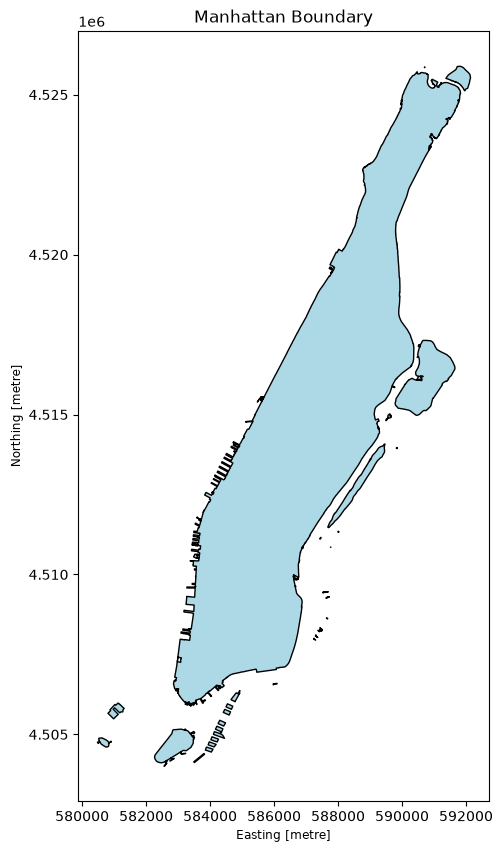

In [6]:
# Select Manhattan
manhattan = boroughs[
    boroughs["boroname"] == "Manhattan"
].copy()

# Convert to a metre-based coordinate system
manhattan = manhattan.to_crs("EPSG:32618")

print("CRS:", manhattan.crs)
print("Bounds:", manhattan.total_bounds)

manhattan.plot(figsize=(6, 10), color="lightblue", edgecolor="black")
plt.title("Manhattan Boundary")
plt.show()

to_crs() transforms the geometry's coordinates into a new coordinate system.  

total_bounds returns four values:  
\[
(min_x,\ min_y,\ max_x,\ max_y)
\]

### 1.3 Generate 500 m grid cells

putting graph paper over Manhattan. Each square is exactly 500 metres wide and 500 metres tall. We create those squares using Shapely's box() function.

In [7]:
CELL_SIZE = 500

minx, miny, maxx, maxy = manhattan.total_bounds

# Generate grid coordinates
x_coords = np.arange(
    np.floor(minx / CELL_SIZE) * CELL_SIZE,
    maxx,
    CELL_SIZE
)

y_coords = np.arange(
    np.floor(miny / CELL_SIZE) * CELL_SIZE,
    maxy,
    CELL_SIZE
)

# Create square polygons
cells = []

for x in x_coords:
    for y in y_coords:
        square = box(
            x,
            y,
            x + CELL_SIZE,
            y + CELL_SIZE
        )
        cells.append(square)

# Convert to GeoDataFrame
grid = gpd.GeoDataFrame(
    geometry=cells,
    crs="EPSG:32618"
)

# Keep cells intersecting Manhattan
boundary = manhattan.geometry.iloc[0]

grid = grid[
    grid.intersects(boundary)
].copy().reset_index(drop=True)

# Assign IDs
grid["cell_id"] = range(len(grid))

print("Number of grid cells:", len(grid))

Number of grid cells: 338


np.arange() generates positions separated by 500 metres.



box(x, y, x+500, y+500) creates one square.



The nested loops produce a rectangular grid.



grid.intersects(boundary) identifies squares touching Manhattan.



cell_id uniquely identifies each grid cell.

### 1.4 Visualize and verify

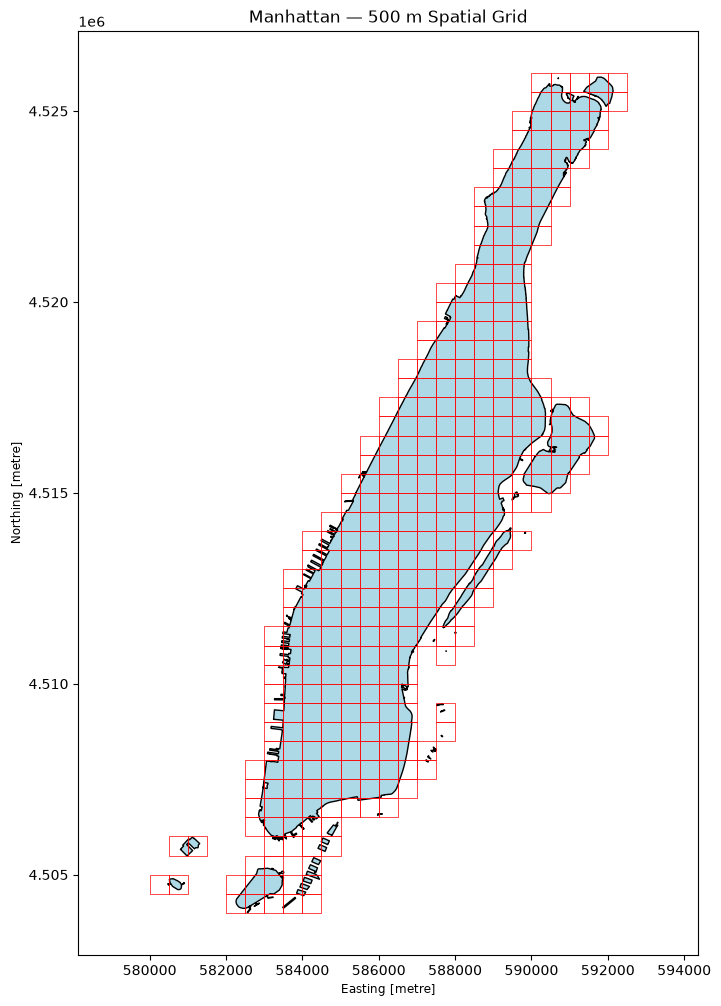

Number of cells: 338
Unique IDs: True
Cell area: 250000.0
Grid verification passed!


In [8]:
fig, ax = plt.subplots(figsize=(8, 12))

manhattan.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black"
)

grid.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=0.5
)

plt.title("Manhattan — 500 m Spatial Grid")
plt.axis("equal")
plt.show()

# Verify cell areas and IDs
print("Number of cells:", len(grid))
print("Unique IDs:", grid["cell_id"].is_unique)
print("Cell area:", grid.geometry.area.iloc[0])

assert np.allclose(grid.geometry.area, 250000)
assert grid["cell_id"].is_unique

print("Grid verification passed!")

## 2 Assign Collisions to Grid Cells

Objective:  
Determine which of our 338 cells contains each collision. 
We have two datasets:  
- grid: 338 polygons, each representing a 500 m square.
- df_clean: Collision records with latitude and longitude.  
A spatial join matches records based on geographic relationships rather than a common ID.  


### 2.1 Load and Convert Collision Points

In [9]:
df_clean = pd.read_csv(
    "../data/processed/manhattan_collision_cleaned.csv", parse_dates=['crash_date']
)

In [10]:
print("Total collisions:", len(df_clean))

Total collisions: 95338


Convert collisions into geographic points

In [11]:
# Convert collisions into geographic points
collisions = gpd.GeoDataFrame(
    df_clean,
    # creates Point geometries from longitude and latitude.
    geometry=gpd.points_from_xy(
        df_clean["longitude"],
        df_clean["latitude"]
    ),
    crs="EPSG:4326"
)

print("Collision CRS:", collisions.crs)

Collision CRS: EPSG:4326


In [12]:
# Keep collisions within Manhattan
#Convert collisions into geographic points
collisions = collisions.to_crs(grid.crs)

print("Collision CRS:", collisions.crs)
print("Grid CRS:", grid.crs)

assert collisions.crs == grid.crs

Collision CRS: EPSG:32618
Grid CRS: EPSG:32618


In [13]:
# Load Manhattan boundary from local files
boroughs = gpd.read_file(
    "../data/raw/borough_boundaries.gpkg"
)

manhattan = boroughs[
    boroughs["boroname"] == "Manhattan"
].copy()

# Convert to same CRS as collisions
manhattan = manhattan.to_crs(collisions.crs)

# Combine Manhattan geometry into one boundary
boundary = manhattan.geometry.union_all()

print("Manhattan CRS:", manhattan.crs)
print("Collisions CRS:", collisions.crs)

assert len(manhattan) == 1
assert manhattan.crs == collisions.crs

Manhattan CRS: EPSG:32618
Collisions CRS: EPSG:32618


- points_from_xy() creates Point geometries from longitude and latitude.
- EPSG:4326 is the coordinate system used by GPS coordinates.
- Each collision now has a geographic Point geometry.  

Note: Our grid uses EPSG:32618, so we must convert the collision points into that same CRS.  

### 2.2 Filter to Manhattan Boundary

In [14]:
inside_manhattan = collisions.geometry.intersects(boundary)

print("Inside Manhattan:", inside_manhattan.sum())
print("Outside Manhattan:", (~inside_manhattan).sum())

Inside Manhattan: 95216
Outside Manhattan: 122


In [15]:
collisions_manhattan = collisions.loc[
    inside_manhattan
].copy()

print("Final collisions:", len(collisions_manhattan))

Final collisions: 95216


### 2.3 Perform the spatial join

We need to convert individual collision locations into grid-level observations. A spatial join assigns each point to the polygon containing it, allowing us to aggregate collisions spatially and temporally.

In [16]:
collisions_grid = gpd.sjoin(
    collisions_manhattan,
    grid[["cell_id", "geometry"]],
    how="left",
    predicate="within"
)

In [17]:
print("Before:", len(collisions_manhattan))
print("After:", len(collisions_grid))

print(
    "Matched:",
    collisions_grid["cell_id"].notna().sum()
)

print(
    "Unmatched:",
    collisions_grid["cell_id"].isna().sum()
)

print(
    "Cells with collisions:",
    collisions_grid["cell_id"].nunique()
)

assert len(collisions_grid) == len(collisions_manhattan)

Before: 95216
After: 95216
Matched: 95216
Unmatched: 0
Cells with collisions: 265


In [18]:
display(
    collisions_grid.loc[
        collisions_grid["cell_id"].isna(),
        ["collision_id", "latitude", "longitude"]
    ]
)

,collision_id,latitude,longitude


## 3 Quarterly Collision Aggregation
Create the dataset that our machine learning models will eventually use.

### 3.1 Aggregate Observed Collisions


In [19]:
collisions_grid.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 95216 entries, 0 to 95337
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   collision_id    95216 non-null  str           
 1   crash_date      95216 non-null  datetime64[us]
 2   crash_time      95216 non-null  str           
 3   borough         95216 non-null  str           
 4   latitude        95216 non-null  float64       
 5   longitude       95216 non-null  float64       
 6   on_street_name  59021 non-null  str           
 7   geometry        95216 non-null  geometry      
 8   index_right     95216 non-null  int64         
 9   cell_id         95216 non-null  int64         
dtypes: datetime64[us](1), float64(2), geometry(1), int64(2), str(4)
memory usage: 12.9 MB


In [20]:
collisions_grid['quarter'] = collisions_grid['crash_date'].dt.to_period("Q")



In [21]:
quarterly_counts = collisions_grid.groupby(['cell_id','quarter']).size().reset_index(name = 'collisions')

In [22]:
quarterly_counts

,cell_id,quarter,collisions
0,10,2019Q2,3
1,10,2019Q3,2
2,10,2020Q3,1
3,10,2020Q4,1
4,10,2021Q2,1
...,...,...,...
6444,334,2024Q4,3
6445,334,2025Q1,1
6446,334,2025Q2,5
6447,334,2025Q3,2


In [23]:
print("Total collisions:", quarterly_counts["collisions"].sum())
print("Unique cells:", quarterly_counts["cell_id"].nunique())
print("Unique quarters:", quarterly_counts["quarter"].nunique())

print("Duplicate cell-quarter pairs:",
      quarterly_counts.duplicated(["cell_id", "quarter"]).sum())

print("Shape:", quarterly_counts.shape)

Total collisions: 95216
Unique cells: 265
Unique quarters: 28
Duplicate cell-quarter pairs: 0
Shape: (6449, 3)


### 3.2 Create the complete cell × quarter dataset

In [24]:
# Get all grid cell IDs
cell_ids = grid["cell_id"].unique()

# Generate all quarters
quarters = pd.period_range("2019Q1", "2025Q4", freq="Q")

# Create all cell-quarter combinations
full_index = pd.MultiIndex.from_product(
    [cell_ids, quarters],
    names=["cell_id", "quarter"]
)

full_index

MultiIndex([(  0, '2019Q1'),
            (  0, '2019Q2'),
            (  0, '2019Q3'),
            (  0, '2019Q4'),
            (  0, '2020Q1'),
            (  0, '2020Q2'),
            (  0, '2020Q3'),
            (  0, '2020Q4'),
            (  0, '2021Q1'),
            (  0, '2021Q2'),
            ...
            (337, '2023Q3'),
            (337, '2023Q4'),
            (337, '2024Q1'),
            (337, '2024Q2'),
            (337, '2024Q3'),
            (337, '2024Q4'),
            (337, '2025Q1'),
            (337, '2025Q2'),
            (337, '2025Q3'),
            (337, '2025Q4')],
           names=['cell_id', 'quarter'], length=9464)

In [25]:

# Convert to DataFrame
full_panel = full_index.to_frame(index=False)

# Merge with observed collision counts
quarterly_panel = full_panel.merge(
    quarterly_counts,
    on=["cell_id", "quarter"],
    how="left",
    validate="one_to_one"
)


In [26]:

# Fill missing combinations with zero collisions
quarterly_panel["collisions"] = (
    quarterly_panel["collisions"]
    .fillna(0)
    .astype(int)
)

# Sort the dataset
quarterly_panel = quarterly_panel.sort_values(
    ["cell_id", "quarter"]
).reset_index(drop=True)

display(quarterly_panel.head())
print("Shape:", quarterly_panel.shape)

,cell_id,quarter,collisions
0,0,2019Q1,0
1,0,2019Q2,0
2,0,2019Q3,0
3,0,2019Q4,0
4,0,2020Q1,0


Shape: (9464, 3)


In [27]:
assert len(quarterly_panel) == len(grid) * len(quarters)

assert (
    quarterly_panel["collisions"].sum()
    == quarterly_counts["collisions"].sum()
)

assert not quarterly_panel.duplicated(
    ["cell_id", "quarter"]
).any()

print("Panel verification passed!")

print(
    "Zero-collision percentage:",
    round((quarterly_panel["collisions"] == 0).mean() * 100, 2)
)

Panel verification passed!
Zero-collision percentage: 31.86


### 3.3 Validate Grid Resolution

In [28]:
#Collision count distribu₹₹tion
quarterly_panel["collisions"].describe()

count    9464.000000
mean       10.060862
std        13.113011
min         0.000000
25%         0.000000
50%         6.000000
75%        15.000000
max       133.000000
Name: collisions, dtype: float64

In [29]:
#Geographic coverage
grid["coverage_ratio"] = (
    grid.geometry.intersection(boundary).area
    / grid.geometry.area
)

print(grid["coverage_ratio"].describe())

print(
    "Cells below 10% Manhattan coverage:",
    (grid["coverage_ratio"] < 0.10).sum()
)

count    338.000000
mean       0.699530
std        0.381294
min        0.000112
25%        0.346408
50%        0.978467
75%        1.000000
max        1.000000
Name: coverage_ratio, dtype: float64
Cells below 10% Manhattan coverage: 51


In [30]:
# Save spatial grid
grid.to_file(
    "../data/processed/manhattan_grid.gpkg",
    driver="GPKG"
)

# Save quarterly collision panel
quarterly_panel.to_csv(
    "../data/processed/quarterly_panel.csv",
    index=False
)

## 4. Road Network Graph Feature
Objective: Extract Manhattan's road network using OSMnx and calculate features for each of our 338 grid cells.

### Road Network Feature Descriptions

| Feature | Description | Interpretation |
|---|---|---|
| `road_length_m` | Total length of road segments within a 500 m grid cell, measured in metres. | Measures road-network coverage within the cell. |
| `major_length_m` | Total length of major roads within the grid cell, measured in metres. | Indicates the extent of major road infrastructure. |
| `major_road_share` | Ratio of major road length to total road length. | Measures the proportion of roads classified as major roads. |
| `intersection_count` | Number of road-network nodes with at least three connected streets within the cell. | Measures the number of intersection-like locations. |
| `intersection_density` | Number of intersections divided by the grid-cell area (0.25 km²). | Measures intersections per square kilometre. |
| `mean_streets_per_node` | Average number of streets connected to road-network nodes within the cell. | Describes local street connectivity. |
| `mean_degree` | Average number of neighboring nodes connected to each road-network node within the cell. | Measures local graph connectivity. |
| `mean_betweenness` | Average approximate, distance-weighted betweenness centrality of nodes within the cell. | Measures average importance along shortest paths across the road network. |
| `max_betweenness` | Maximum approximate, distance-weighted betweenness centrality among nodes within the cell. | Identifies whether the cell contains a particularly important network connection. |

**Feature Categories:**

- **Road Geometry:** `road_length_m`, `major_length_m`, `major_road_share`
- **Intersection and Connectivity:** `intersection_count`, `intersection_density`, `mean_streets_per_node`
- **Graph Topology (NetworkX):** `mean_degree`, `mean_betweenness`, `max_betweenness`

**Final Dataset:** 338 grid cells × 10 columns (9 graph features + `cell_id`).

**Note:** These features describe road-network structure and connectivity, not actual traffic volume. Their contribution to collision forecasting will be evaluated through model comparisons.

### 4.1 Download the Manhattan road network

In [31]:
print("OSMnx version:", ox.__version__)

OSMnx version: 2.1.1


In [32]:
#Retrieve the road network
# Convert the boundary back to latitude/longitude
manhattan_wgs84 = manhattan.to_crs("EPSG:4326")
polygon = manhattan_wgs84.geometry.union_all()

# Download Manhattan's drivable road network
G = ox.graph.graph_from_polygon(
    polygon,
    network_type="drive",
    simplify=True,
    retain_all=True
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 4654
Edges: 9953


In [33]:
#Path("../data/raw").mkdir(parents=True, exist_ok=True)

ox.io.save_graphml(
    G,
    filepath="../data/raw/manhattan_roads.graphml"
)

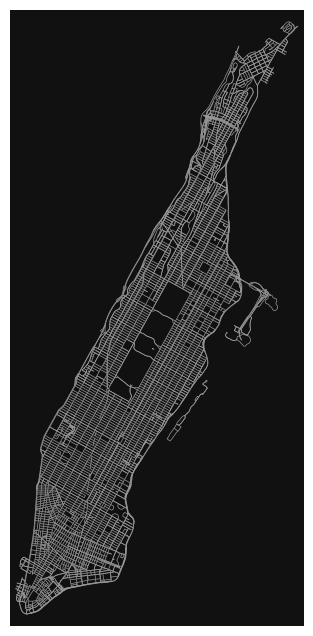

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [34]:
ox.plot.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.5
)

In [35]:
# # Convert graph coordinates to metres
G_proj = ox.projection.project_graph(
    G,
    to_crs=grid.crs
)

# Extract graph nodes
nodes = ox.convert.graph_to_gdfs(
    G_proj,
    edges=False
)

# Convert to undirected to avoid counting
# two-way road segments twice
G_undirected = ox.convert.to_undirected(G_proj)

# Extract road segments
edges = ox.convert.graph_to_gdfs(
    G_undirected,
    nodes=False
)

print("Nodes:", len(nodes))
print("Road segments:", len(edges))
print("CRS:", nodes.crs)

Nodes: 4654
Road segments: 8241
CRS: EPSG:32618


### Calculate grid-level graph features

In [36]:
# Keep only roads inside Manhattan's boundary
roads = gpd.clip(
    edges[["highway", "geometry"]],
    boundary
)

# Split road geometries at grid-cell boundaries
road_segments = gpd.overlay(
    roads,
    grid[["cell_id", "geometry"]],
    how="intersection",
    keep_geom_type=False
)

# Calculate clipped road lengths
road_segments["segment_length"] = (
    road_segments.geometry.length
)

# Identify major road classes
major_types = {
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link"
}

def is_major(highway):
    types = highway if isinstance(highway, list) else [highway]
    return any(h in major_types for h in types)

road_segments["major_length"] = (
    road_segments["segment_length"]
    * road_segments["highway"].apply(is_major)
)

road_features = (
    road_segments.groupby("cell_id")
    .agg(
        road_length_m=("segment_length", "sum"),
        major_length_m=("major_length", "sum")
    )
    .reset_index()
)

road_features["major_road_share"] = (
    road_features["major_length_m"]
    / road_features["road_length_m"]
)

display(road_features.head())

,cell_id,road_length_m,major_length_m,major_road_share
0,9,39.248793,0.000000,0.000000
1,10,576.514509,0.000000,0.000000
2,11,61.277930,0.000000,0.000000
3,17,4646.556117,2991.827547,0.643881
4,18,6777.004882,3576.111254,0.527683


### Intersection density and connectivity

In [37]:
# Assign network nodes to grid cells
nodes_grid = gpd.sjoin(
    nodes[["street_count", "geometry"]],
    grid[["cell_id", "geometry"]],
    how="inner",
    predicate="within"
)

# Aggregate node features
node_features = (
    nodes_grid.groupby("cell_id")
    .agg(
        intersection_count=(
            "street_count",
            lambda x: (x >= 3).sum()
        ),
        mean_streets_per_node=(
            "street_count",
            "mean"
        )
    )
    .reset_index()
)

# Each grid cell is 0.25 square kilometres
node_features["intersection_density"] = (
    node_features["intersection_count"] / 0.25
)

display(node_features.head())

,cell_id,intersection_count,mean_streets_per_node,intersection_density
0,10,3,2.166667,12.0
1,11,1,3.000000,4.0
2,17,28,3.285714,112.0
3,18,42,3.325581,168.0
4,19,12,3.384615,48.0


#### Calculate NetworkX degree and betweenness

In [38]:
import networkx as nx

# Convert MultiGraph to a simple undirected graph.
# Retain the shortest road length if parallel edges exist.
H = nx.Graph()
H.add_nodes_from(G_undirected.nodes())

for u, v, data in G_undirected.edges(data=True):
    if u == v:
        continue

    length = float(data["length"])

    if not H.has_edge(u, v) or length < H[u][v]["length"]:
        H.add_edge(u, v, length=length)

# Degree: number of neighboring nodes
degree = dict(H.degree())

# Approximate distance-weighted betweenness centrality
betweenness = nx.betweenness_centrality(
    H,
    k=min(100, H.number_of_nodes()),
    weight="length",
    normalized=True,
    seed=42
)

# Attach scores to geographic nodes
topology_nodes = nodes[["geometry"]].copy()

topology_nodes["degree"] = topology_nodes.index.map(degree)
topology_nodes["betweenness"] = topology_nodes.index.map(betweenness)

display(topology_nodes[["degree", "betweenness"]].describe())

,degree,betweenness
count,4654.000000,4654.000000
mean,3.530726,0.016587
std,0.677397,0.022581
min,1.000000,0.000000
25%,3.000000,0.001749
50%,4.000000,0.008616
75%,4.000000,0.022709
max,5.000000,0.161902


In [39]:
topology_grid = gpd.sjoin(
    topology_nodes,
    grid[["cell_id", "geometry"]],
    how="inner",
    predicate="within"
)

topology_features = (
    topology_grid.groupby("cell_id")
    .agg(
        mean_degree=("degree", "mean"),
        mean_betweenness=("betweenness", "mean"),
        max_betweenness=("betweenness", "max")
    )
    .reset_index()
)

display(topology_features.head())

,cell_id,mean_degree,mean_betweenness,max_betweenness
0,10,1.833333,0.000058,0.000331
1,11,1.000000,0.000000,0.000000
2,17,3.214286,0.000620,0.001969
3,18,3.232558,0.001662,0.006892
4,19,3.230769,0.002620,0.005376


### Combine and save graph features

In [40]:
graph_features = (
    grid[["cell_id"]]
    .merge(road_features, on="cell_id", how="left")
    .merge(node_features, on="cell_id", how="left")
    .merge(topology_features, on="cell_id", how="left")
)

feature_cols = [
    "road_length_m",
    "major_length_m",
    "major_road_share",
    "intersection_count",
    "intersection_density",
    "mean_streets_per_node",
    "mean_degree",
    "mean_betweenness",
    "max_betweenness"
]

graph_features[feature_cols] = (
    graph_features[feature_cols].fillna(0)
)

display(graph_features.head())

,cell_id,road_length_m,major_length_m,major_road_share,intersection_count,mean_streets_per_node,intersection_density,mean_degree,mean_betweenness,max_betweenness
0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [41]:
print("Shape:", graph_features.shape)

print(
    graph_features[
        ["mean_degree", "mean_betweenness", "max_betweenness"]
    ].describe()
)

assert len(graph_features) == 338
assert graph_features["cell_id"].is_unique
assert graph_features[feature_cols].notna().all().all()

Shape: (338, 10)
       mean_degree  mean_betweenness  max_betweenness
count   338.000000        338.000000       338.000000
mean      2.681848          0.012601         0.030294
std       1.445820          0.014537         0.033215
min       0.000000          0.000000         0.000000
25%       2.381250          0.000251         0.000629
50%       3.320513          0.008007         0.022266
75%       3.683612          0.019342         0.047061
max       4.000000          0.070962         0.161902


In [42]:
assert len(graph_features) == len(grid)
assert graph_features["cell_id"].is_unique

assert graph_features[feature_cols].notna().all().all()
assert graph_features["road_length_m"].ge(0).all()

assert graph_features["major_road_share"].between(0, 1).all()

print("Graph features verified!")
print("Shape:", graph_features.shape)

graph_features.to_csv(
    "../data/processed/graph_features.csv",
    index=False
)

Graph features verified!
Shape: (338, 10)


In [43]:
print(graph_features[
    ["mean_degree", "mean_betweenness", "max_betweenness"]
].describe())

       mean_degree  mean_betweenness  max_betweenness
count   338.000000        338.000000       338.000000
mean      2.681848          0.012601         0.030294
std       1.445820          0.014537         0.033215
min       0.000000          0.000000         0.000000
25%       2.381250          0.000251         0.000629
50%       3.320513          0.008007         0.022266
75%       3.683612          0.019342         0.047061
max       4.000000          0.070962         0.161902


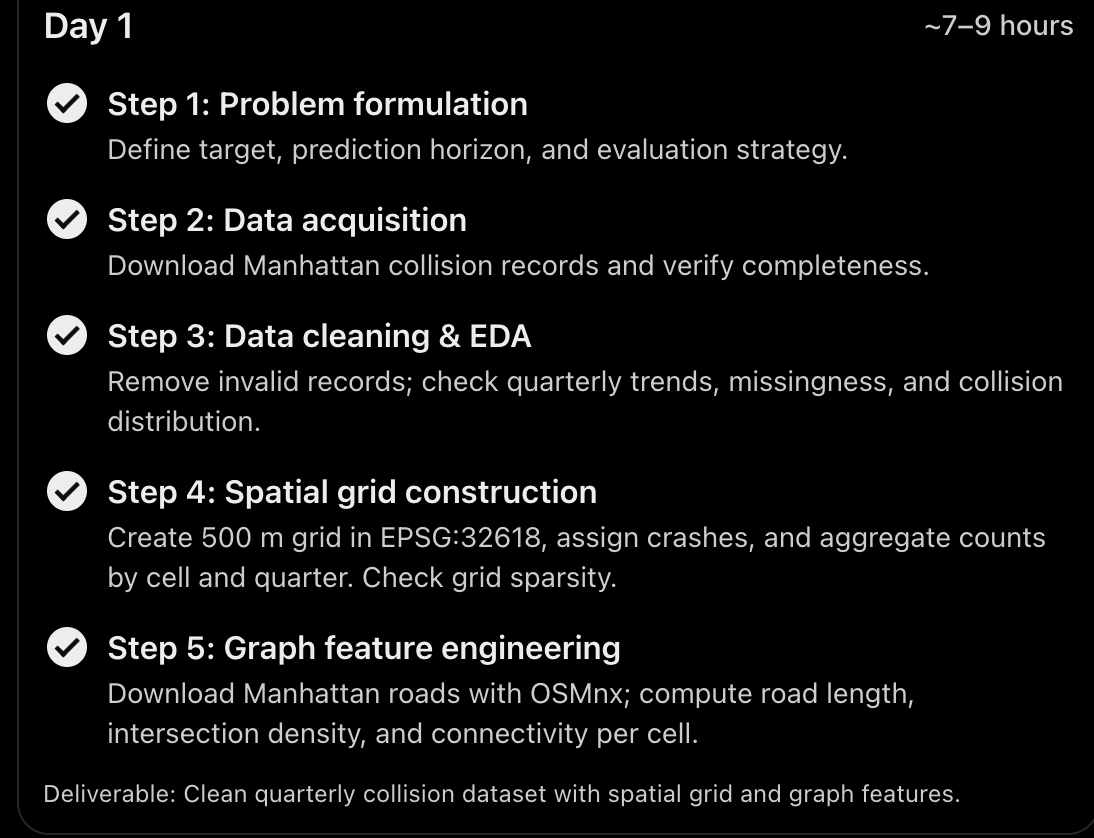